In [59]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [60]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

## Description des variables

Le jeu de données contient **3 253 annonces de téléphones** décrites par **7 variables** : 6 variables explicatives et 1 variable cible (`etat`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `prix` | Numérique (continue) | Prix du téléphone dans l'annonce | 1 – 3 335 000 (médiane ≈ 362 043) |
| `adresse` | Catégorielle | Quartier / zone de l'annonce | 43 modalités, les plus fréquentes : `Plateau`, `Médina`, `Nord foire`, `Colobane` |
| `marque` | Catégorielle | Marque du téléphone | 28 modalités, les plus fréquentes : `iPhone`, `Samsung`, `iPad`, `ZTE` |
| `dim_ecr` | Numérique (continue) | Dimension de l'écran, en pouces | 0,0 – 75,0 pouces (médiane ≈ 6,0) |
| `ram` | Numérique (discrète) | Mémoire RAM, en Go | 1 – 512 Go (médiane ≈ 12) |
| `stockage` | Numérique (discrète) | Capacité de stockage, en Go | 1 – 5 120 Go (médiane ≈ 158) |
| **`etat`** | Catégorielle | **Variable cible** : état du téléphone | 4 classes : `D'occasion` (756), `Neuf` (665), `Réconditionné` (1053), `Venant` (779) |


### <font color = 'teal'>Importer et Lire les données<font>

In [61]:
# importer les données
df = pd.read_csv('Telephone_data.csv')
df.head()

,prix,adresse,marque,dim_ecr,ram,stockage,etat
0,580000,Guediawaye,iPhone,6.0,8,128,D'occasion
1,250000,Mermoz,iPhone,6.0,4,128,D'occasion
2,80000,Médina,iPhone,5.0,5,128,D'occasion
3,290000,Plateau,Samsung,6.0,8,256,D'occasion
4,250000,Mermoz,Samsung,6.0,8,256,D'occasion


In [62]:
# dimension des données
df.shape

(3253, 7)

In [63]:
# infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3253 entries, 0 to 3252
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   prix      3253 non-null   int64  
 1   adresse   3253 non-null   str    
 2   marque    3253 non-null   str    
 3   dim_ecr   3253 non-null   float64
 4   ram       3253 non-null   int64  
 5   stockage  3253 non-null   int64  
 6   etat      3253 non-null   str    
dtypes: float64(1), int64(3), str(3)
memory usage: 178.0 KB


In [64]:
# valeurs manquantes
df.isnull().sum()

prix        0
adresse     0
marque      0
dim_ecr     0
ram         0
stockage    0
etat        0
dtype: int64

### <font color = 'teal'>Exploration et preparation des données<font>



###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [65]:
# selection les variables catégorielles
df.select_dtypes(include='object').columns
# df.select_dtypes(exclude='number').columns

Index(['adresse', 'marque', 'etat'], dtype='str')

In [66]:
cat_data = df.select_dtypes(include='object')
# cat_data = df.select_dtypes(include='object')
cat_data.head()

,adresse,marque,etat
0,Guediawaye,iPhone,D'occasion
1,Mermoz,iPhone,D'occasion
2,Médina,iPhone,D'occasion
3,Plateau,Samsung,D'occasion
4,Mermoz,Samsung,D'occasion


In [67]:
# selection des variables quantitatives
df.select_dtypes(include='object').columns
# df.select_dtypes(include='number').columns
df.describe().columns

Index(['prix', 'dim_ecr', 'ram', 'stockage'], dtype='str')

In [68]:
quant_data = df.select_dtypes(include='number')
quant_data.head()

,prix,dim_ecr,ram,stockage
0,580000,6.0,8,128
1,250000,6.0,4,128
2,80000,5.0,5,128
3,290000,6.0,8,256
4,250000,6.0,8,256


###### <font color = 'bisque'> Exploration des variables catégorielles

In [69]:
# décrire les variables catégorielles
cat_data.describe(include='object')

,adresse,marque,etat
count,3253,3253,3253
unique,43,28,4
top,Plateau,iPhone,Réconditionné
freq,415,1571,1053


In [70]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

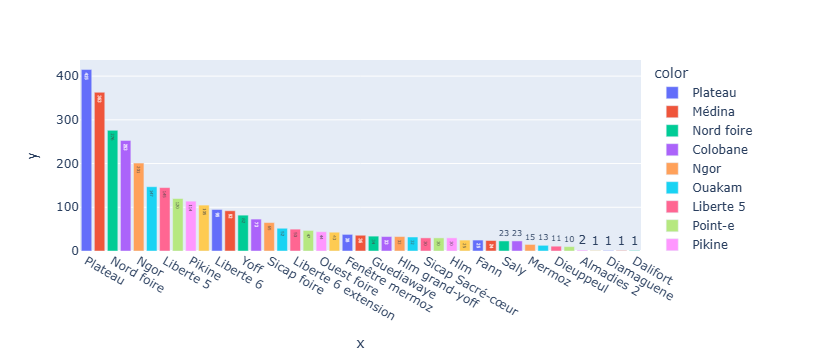

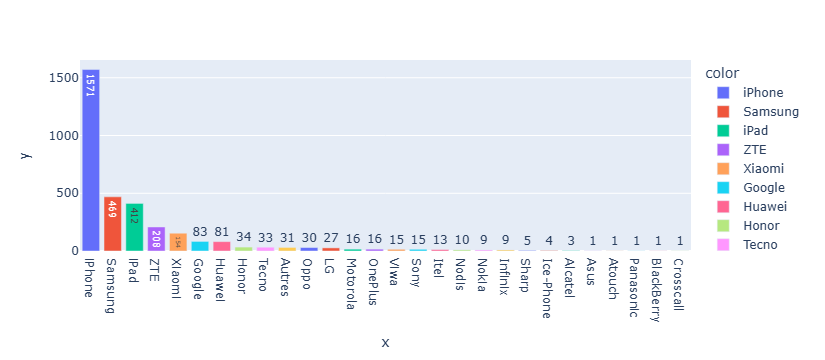

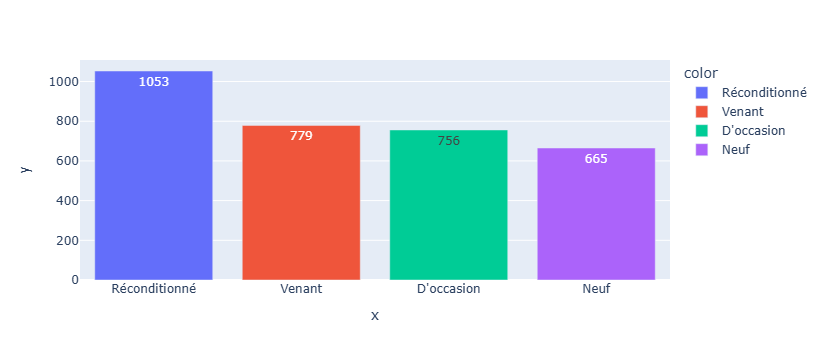

In [71]:
# Diagrammes en barre des variables catégorielles
for col in cat_data.columns:
  countplot_func(col)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [72]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
prix,3253.0,360830.307101,215801.003089,1.0,237043.0,362043.0,462044.0,3335000.0
dim_ecr,3253.0,6.510913,3.466092,0.0,6.0,6.0,7.0,75.0
ram,3253.0,16.377498,20.291301,1.0,11.0,12.0,14.0,512.0
stockage,3253.0,193.514294,169.625904,1.0,128.0,158.0,256.0,5120.0


si on avait une variable ayant unique qui n'a que 1 modalite alors on peut s'en debarrasser

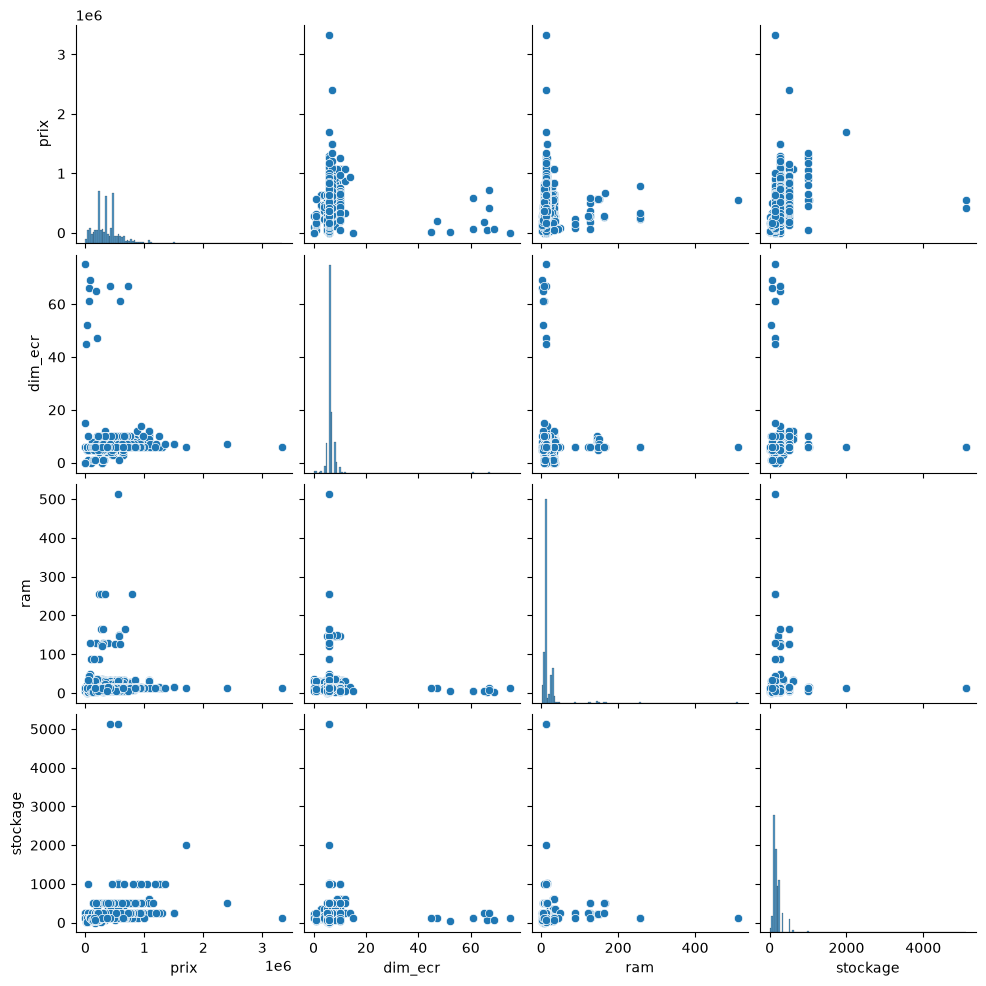

In [73]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

In [74]:
# matrice de correlation
quant_data.corr()

,prix,dim_ecr,ram,stockage
prix,1.000000,0.040199,0.159535,0.359586
dim_ecr,0.040199,1.000000,0.024216,0.027186
ram,0.159535,0.024216,1.000000,0.095711
stockage,0.359586,0.027186,0.095711,1.000000


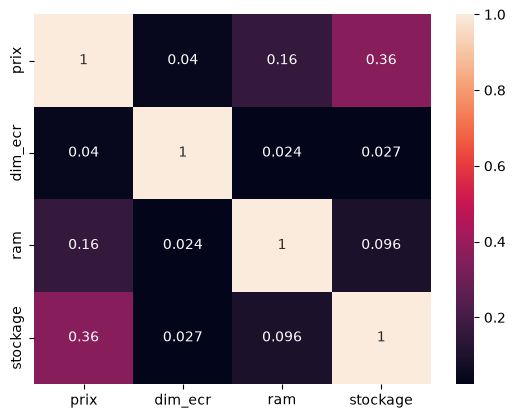

In [75]:
# heatmap  de la matrice de correlation
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [76]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

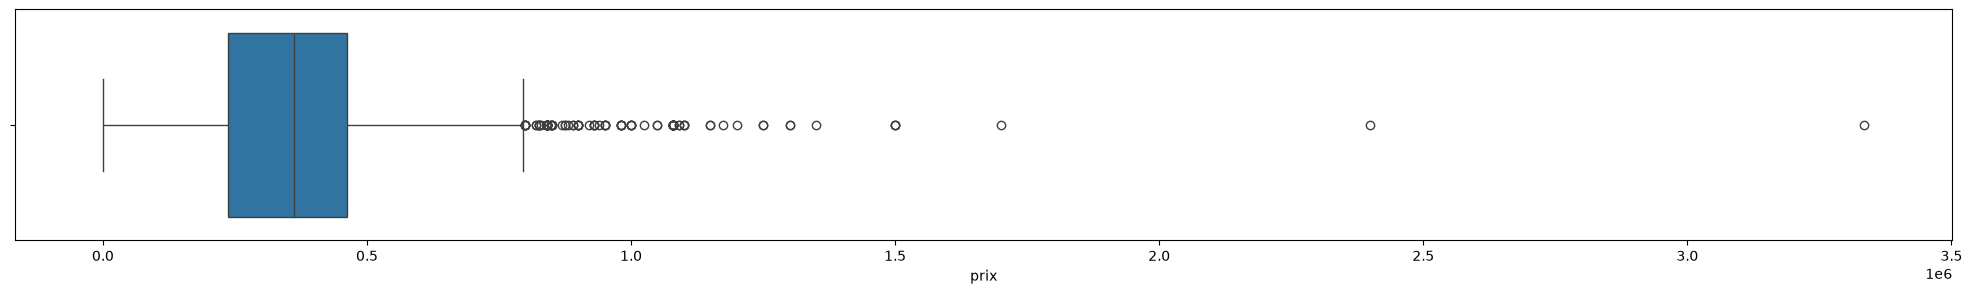

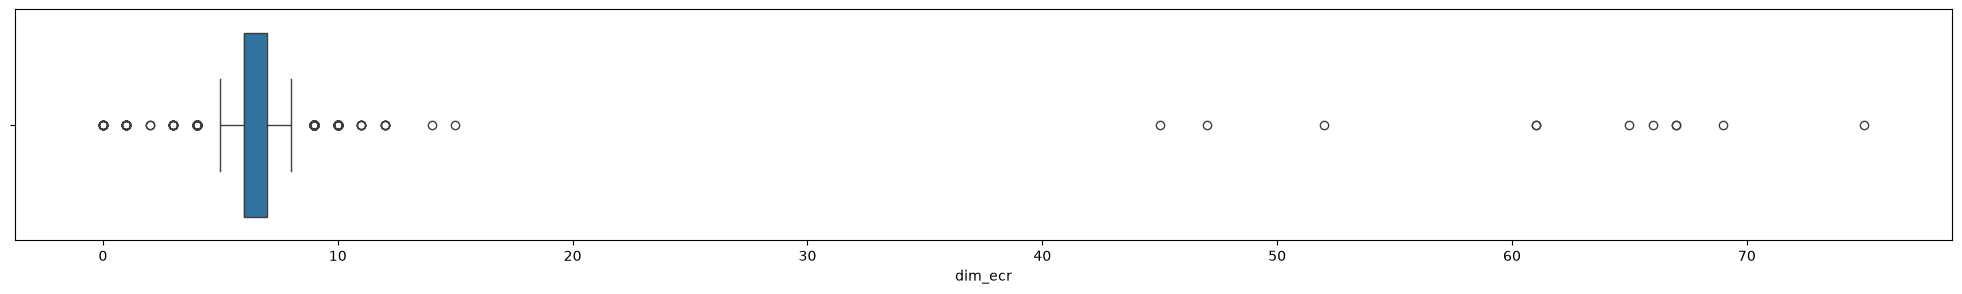

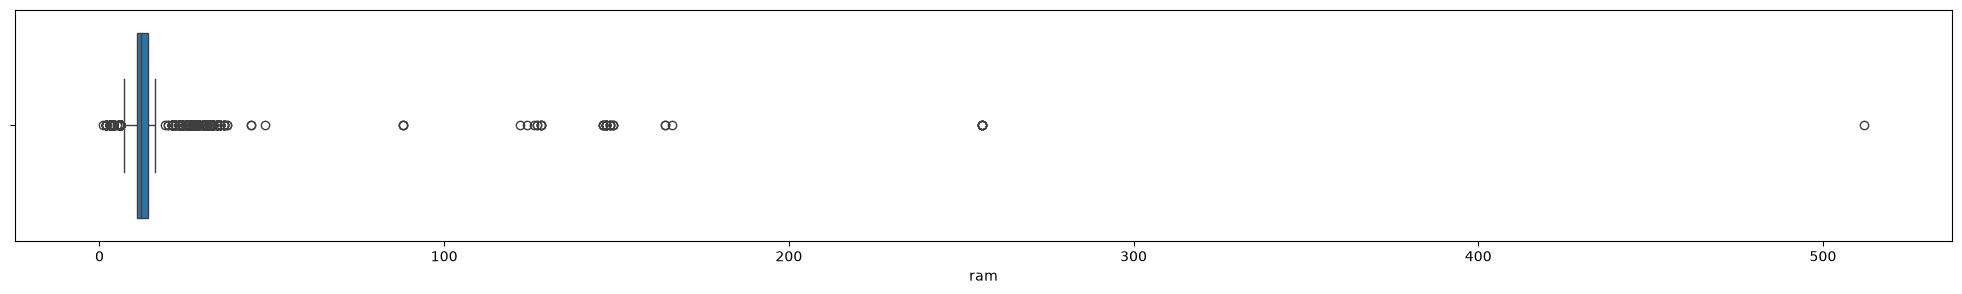

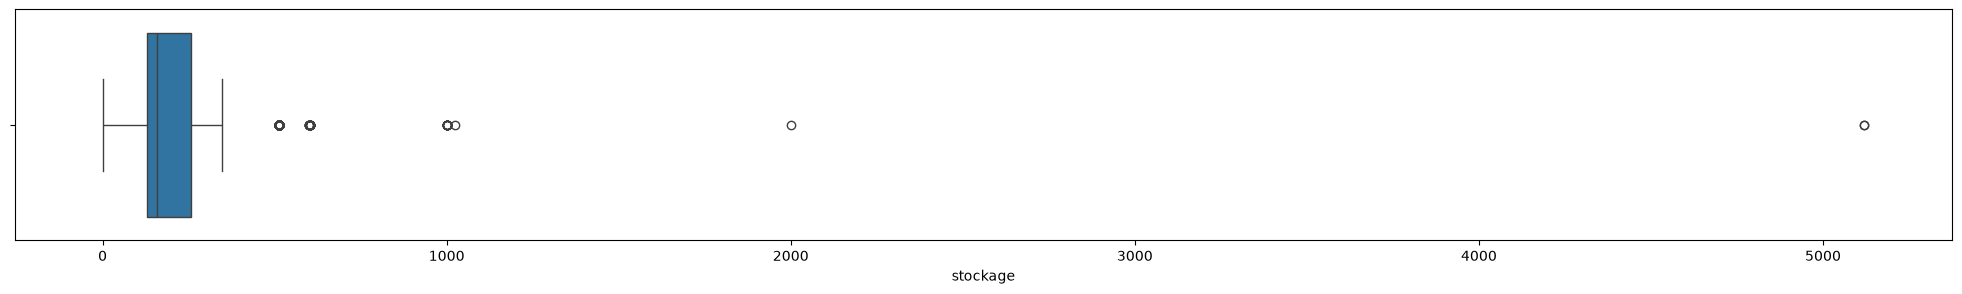

In [77]:
# boxplots des variables quantitatives
for col in quant_data.columns:
  boxplot_func(col)

###### <font color = 'bisque'> Preparation des données

In [117]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# sauvegarde
import joblib as jb
jb.dump(uniques, 'uniques_clas1.joblib')

['uniques_clas1.joblib']

In [118]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# cette bibliotheque le fait selon l'ordre alphabetique
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(cat_data.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[cat_data.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat_data.columns[i]] = encoder.transform(df[cat_data.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

In [119]:
import joblib as jb
# sauvegarde les encodeurs
jb.dump(encoders, 'encoders_clas1.joblib')

['encoders_clas1.joblib']

In [81]:
df.head()

,prix,adresse,marque,dim_ecr,ram,stockage,etat
0,580000,13,27,6.0,8,128,0
1,250000,22,27,6.0,4,128,0
2,80000,23,27,5.0,5,128,0
3,290000,32,19,6.0,8,256,0
4,250000,22,19,6.0,8,256,0


In [82]:
from sklearn.impute import KNNImputer
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1 # interquantile
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [83]:
# imputation des valeurs extremes
for col in quant_data.columns:
  impute_func(df, col)

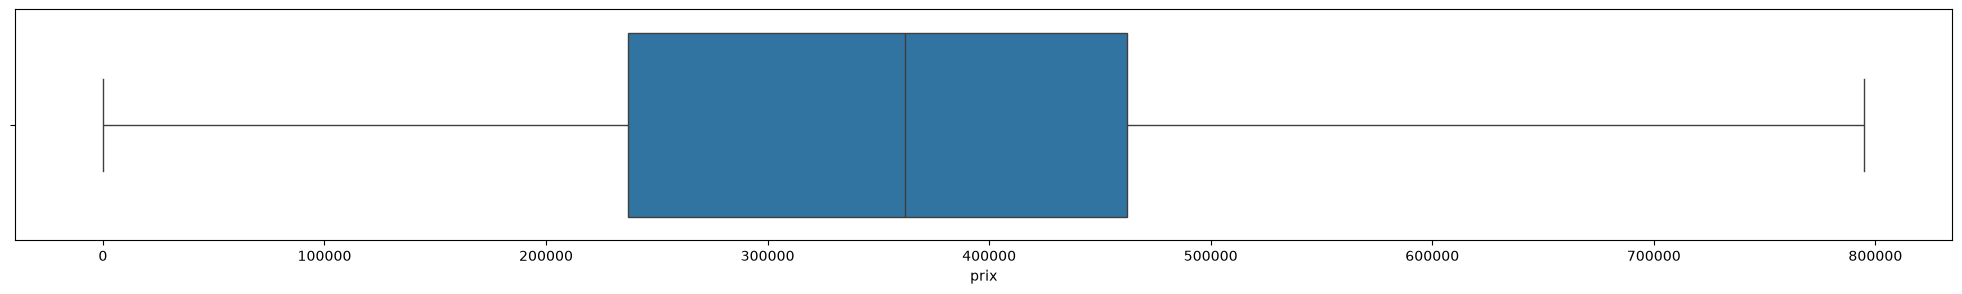

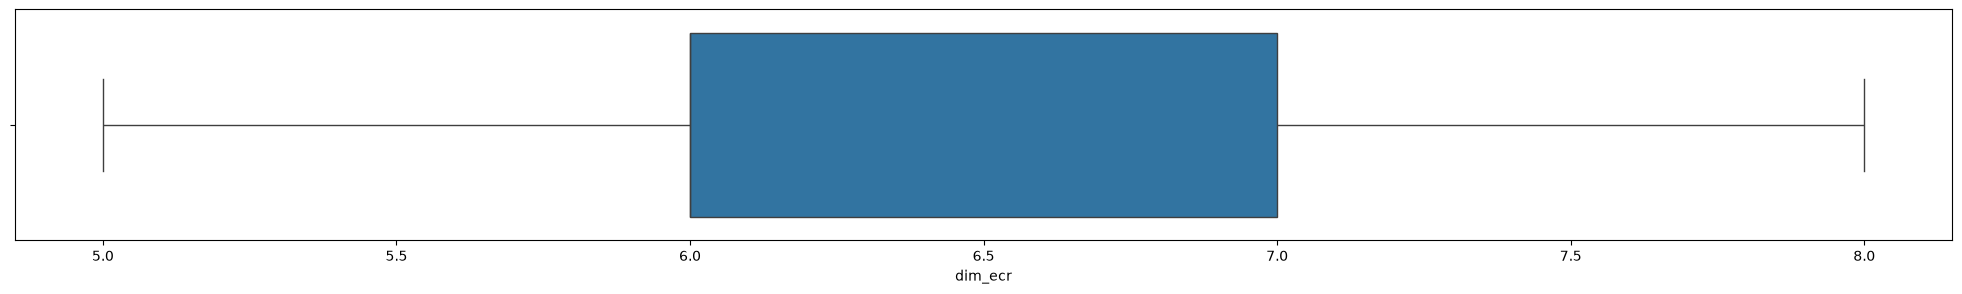

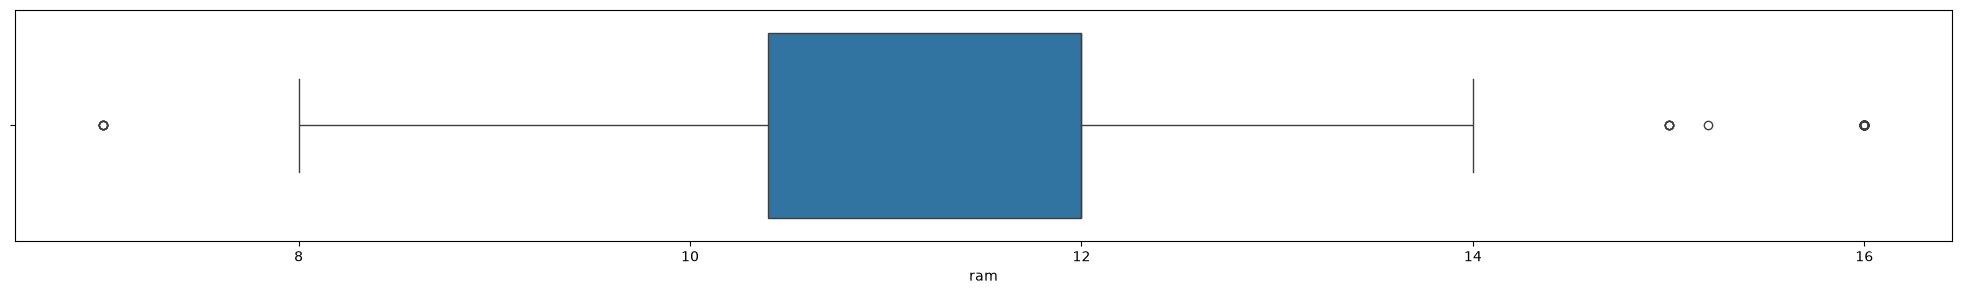

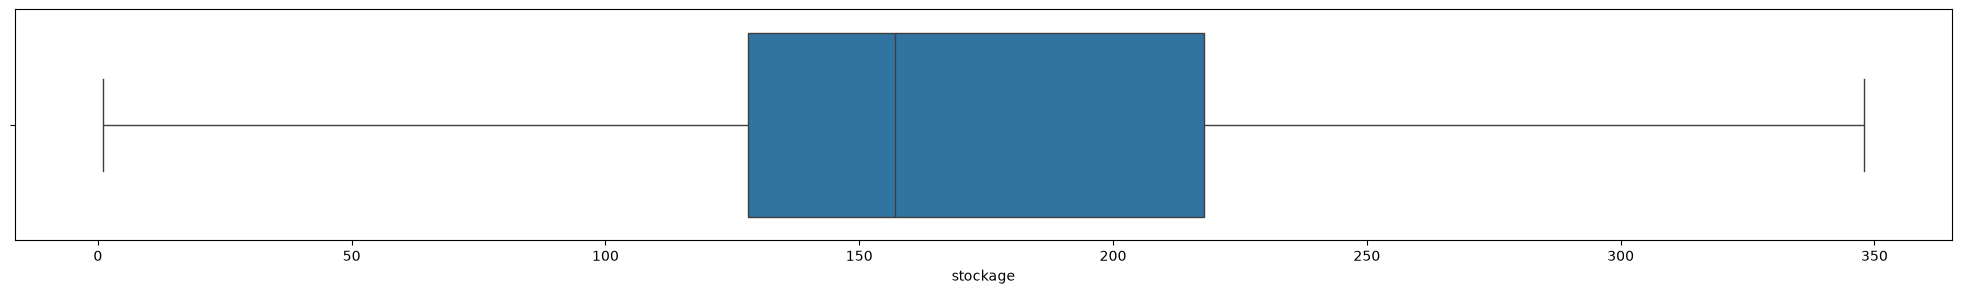

In [84]:
for col in quant_data.columns:
  boxplot_func(col)

In [85]:
# Fractionner les données en variables prédicteurs (x) et variable cible(y)
# x = df.iloc[:, :-1]
x = df.drop('etat', axis=1).values
y = df.etat.values
x[:5], y[:5]

(array([[5.80e+05, 1.30e+01, 2.70e+01, 6.00e+00, 8.00e+00, 1.28e+02],
        [2.50e+05, 2.20e+01, 2.70e+01, 6.00e+00, 1.12e+01, 1.28e+02],
        [8.00e+04, 2.30e+01, 2.70e+01, 5.00e+00, 1.04e+01, 1.28e+02],
        [2.90e+05, 3.20e+01, 1.90e+01, 6.00e+00, 8.00e+00, 2.56e+02],
        [2.50e+05, 2.20e+01, 1.90e+01, 6.00e+00, 8.00e+00, 2.56e+02]]),
 array([0, 0, 0, 0, 0]))

In [86]:
# normaliser les données
from sklearn.preprocessing import MinMaxScaler # Z = (X - Xmin)/(Xmax -Xmin)
scaler = MinMaxScaler()
x = scaler.fit_transform(x)
x[:5]

array([[0.72955941, 0.30952381, 1.        , 0.33333333, 0.11111111,
        0.36599424],
       [0.31446455, 0.52380952, 1.        , 0.33333333, 0.46666667,
        0.36599424],
       [0.1006278 , 0.54761905, 1.        , 0.        , 0.37777778,
        0.36599424],
       [0.36477908, 0.76190476, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032],
       [0.31446455, 0.52380952, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032]])

In [120]:
# sauvegarde du scaler
jb.dump(scaler,'scaler_clas1.joblib')

['scaler_clas1.joblib']

In [127]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y, train_size= 0.8, random_state= 42)
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test, train_size= 0.5, random_state= 42)


### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [89]:
from sklearn.model_selection import GridSearchCV , KFold
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.linear_model import LogisticRegression

# validation croisee
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params={"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# instantier le modèle Logistic regression
lg=LogisticRegression()
# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=5)
# lancer la recherche
grid.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'penalty': ['l1', 'l2']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printe

In [90]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(0.46415888336127775), 'penalty': 'l2'}

###### <font color = 'bisque'> Entrainement du modèle

In [91]:
# Récupérer le modèle optimal en partant de gridsearch
lg_model = grid.best_estimator_

###### <font color ='bisque'>Evaluation du modèle

In [92]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [93]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(lg_model)
print(f"Accuracy : {acc_lg} --- F1 score : {f1_lg}")

Accuracy : 0.68 --- F1 score : 0.68


In [94]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1,2,3])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Occasion','Neuf', 'Reconditionné','Venant'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

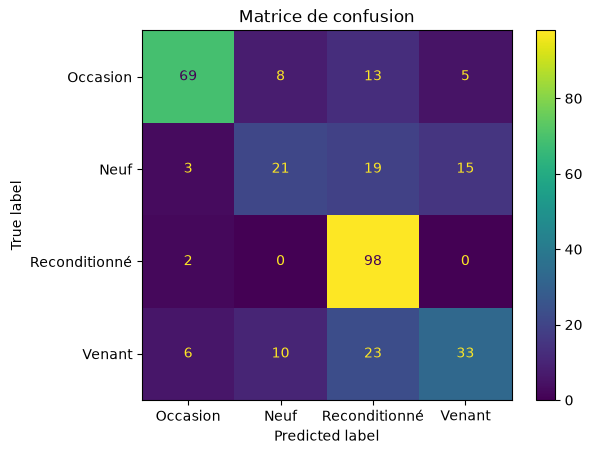

In [95]:
# Matrice de confusion
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [96]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = cv)
# entrainer le modèle
grid__.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defa

In [97]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(13)}

###### <font color = 'bisque'> Entrainement du modèle

In [98]:
# Récupérer le modèle optimal en partant de gridsearch
dt_model = grid__.best_estimator_

###### <font color ='bisque'>Evaluation du modèle<font>

In [99]:
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy : {acc_dt} --- F1 score : {f1_dt}")

Accuracy : 0.8092307692307692 --- F1 score : 0.8092307692307692


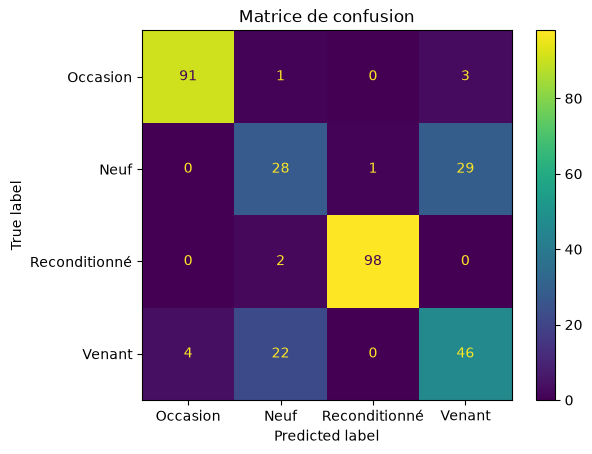

In [100]:
# Matrice de confusion
CM_visualisation(dt_model)

### <font color = 'teal'>Random Forest<font>

In [101]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= cv)
# entrainer le modèle
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support f

In [102]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'gini', 'max_depth': np.int64(11), 'n_estimators': np.int64(80)}

In [110]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model_clas1 = grid.best_estimator_

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [111]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf, f1_rf = evaluation(rf_model_clas1)
print(f"Accuracy : {acc_rf} --- F1 score : {f1_rf}")

Accuracy : 0.8646153846153846 --- F1 score : 0.8646153846153846


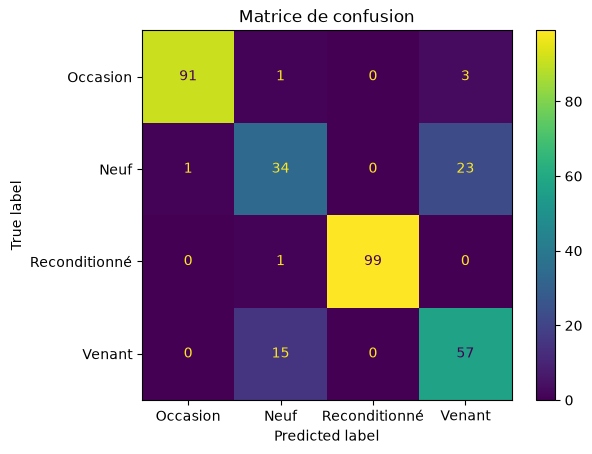

In [112]:
# Matrice de confusion
CM_visualisation(rf_model_clas1)

### <font color ='bisque'>Tester le modèle le plus performant<font>

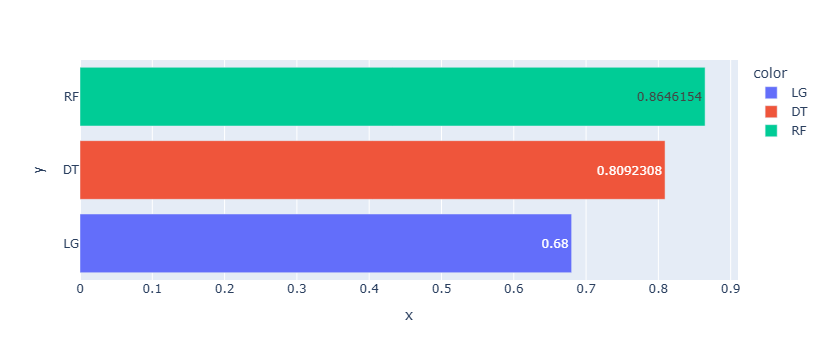

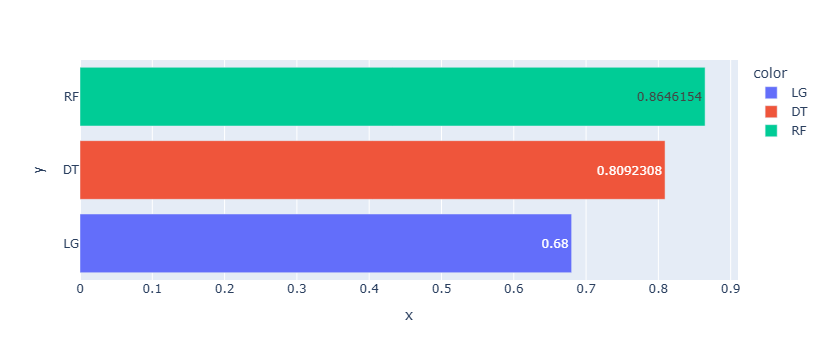

In [113]:
# diagramme des peformances
list_names = ['LG', 'DT', 'RF']
list_acc = [acc_lg, acc_dt, acc_rf]
list_f1 = [f1_lg, f1_dt, f1_rf]
list_final = [list_acc, list_f1]
for i in range(2):
  fig = px.bar(y=list_names, x = list_final[i], color = list_names, text_auto= True)
  fig.show()

In [114]:
# télécharger le modèle le plus performant
jb.dump(rf_model_clas1, 'rf_model_clas1.joblib')

['rf_model_clas1.joblib']

In [116]:
# echantillons
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# predictions
y_pred_10 = rf_model_clas1.predict(x_test_10)
classnames = ['occasion', 'neuf', 'reconditionne', 'venant']
for i in range(10):
 print(f"prediction {str(i+1)} : {classnames[y_pred_10[i]]} -- {classnames[y_test_10[i]]}")

prediction 1 : venant -- venant
prediction 2 : neuf -- neuf
prediction 3 : occasion -- occasion
prediction 4 : occasion -- occasion
prediction 5 : occasion -- occasion
prediction 6 : reconditionne -- reconditionne
prediction 7 : venant -- venant
prediction 8 : neuf -- venant
prediction 9 : reconditionne -- reconditionne
prediction 10 : venant -- venant


In [132]:
print("Dimensions de x_train :", x_train.shape)

print("Noms des colonnes utilisées :")
print(COLONNES if "COLONNES" in globals() else df.drop("etat", axis=1).columns.tolist())

Dimensions de x_train : (2602, 6)
Noms des colonnes utilisées :
['prix', 'adresse', 'marque', 'dim_ecr', 'ram', 'stockage']


In [133]:
for i, encoder in enumerate(encoders):

    print("\nEncodeur :", i)

    print("Classes :", encoder.classes_)


Encodeur : 0
Classes : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42]

Encodeur : 1
Classes : [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27]

Encodeur : 2
Classes : [0 1 2 3]


In [136]:
for colonne in ["adresse", "marque"]:

    verification = pd.DataFrame({
        "original": df_original[colonne].astype(str).str.strip(),
        "code": df[colonne].astype(int)
    })

    correspondances = verification.drop_duplicates()

    print("\nCorrespondances :", colonne)
    display(correspondances.sort_values("code"))


Correspondances : adresse


,original,code
17,Almadies,0
2820,Almadies 2,1
2768,Biscuiterie,2
18,Castor,3
31,Cité Damel,4
1848,Colobane,5
3251,Dalifort,6
2143,Diamaguene,7
125,Dieuppeul,8
71,Fann,9



Correspondances : marque


,original,code
2228,Alcatel,0
23,Asus,1
1851,Atouch,2
1852,Autres,3
2285,BlackBerry,4
2308,Crosscall,5
5,Google,6
59,Honor,7
14,Huawei,8
239,Ice-Phone,9
